# Prediksi Produksi Karet 2025 per Provinsi — Regresi Linier

# IMPORT LIBRARY

In [22]:
# 202431026_Purnomo Jeremy Bambang
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

## MEMBACA DATASET

In [23]:
# 202431026_Purnomo Jeremy Bambang
df = pd.read_excel('19_Jumlah_Produksi_Karet.xlsx',
                   na_values = '-',
                   skiprows=11,
                   header=None)

df.columns = ['No', 'Provinsi', '2020', '2021', '2022', '2023', '2024', 'Pertumbuhan (%)']
df = df.drop(columns=['No', 'Pertumbuhan (%)'])

df = df[df['Provinsi'].notna()].reset_index(drop=True)
df

,Provinsi,2020,2021,2022,2023,2024
0,Aceh,79107.8,80970.63708,66082.78550,53256.68,51173.0
1,Sumatera Utara,321351.3,321554.38325,316829.18281,269200.57,251518.0
2,Sumatera Barat,136984.6,137410.38563,126877.81657,108415.29,99666.0
3,Riau,299178.7,299434.27700,222296.01968,189589.90,180742.0
4,Jambi,298875.0,301021.88867,294768.88477,234046.71,222556.0
5,Sumatera Selatan,867566.7,882889.12354,783321.71561,639302.71,619546.0
6,Bengkulu,100171.6,97874.56323,89794.87302,71570.78,64599.0
7,Lampung,139414.3,131421.59495,121592.85690,88924.23,84832.0
8,Kepulauan Bangka Belitung,47686.2,47789.58900,39823.55500,29287.58,26035.0
9,Kepulauan Riau,15490.4,15801.90070,11120.69900,9725.05,8405.0


# EDA

In [24]:
# 202431026_Purnomo Jeremy Bambang
df.head()

,Provinsi,2020,2021,2022,2023,2024
0,Aceh,79107.8,80970.63708,66082.78550,53256.68,51173.0
1,Sumatera Utara,321351.3,321554.38325,316829.18281,269200.57,251518.0
2,Sumatera Barat,136984.6,137410.38563,126877.81657,108415.29,99666.0
3,Riau,299178.7,299434.27700,222296.01968,189589.90,180742.0
4,Jambi,298875.0,301021.88867,294768.88477,234046.71,222556.0


In [25]:
# 202431026_Purnomo Jeremy Bambang
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38 entries, 0 to 37
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Provinsi  38 non-null     object 
 1   2020      38 non-null     float64
 2   2021      35 non-null     float64
 3   2022      38 non-null     float64
 4   2023      38 non-null     float64
 5   2024      38 non-null     float64
dtypes: float64(5), object(1)
memory usage: 1.9+ KB


In [26]:
# 202431026_Purnomo Jeremy Bambang
cols_tahun = ['2020', '2021', '2022', '2023', '2024']
print('Missing value per kolom:')
print(df.isna().sum())
print(f"\nTotal sel data : {df[cols_tahun].size}")
print(f"Total missing  : {df[cols_tahun].isna().sum().sum()} ({df[cols_tahun].isna().sum().sum()/df[cols_tahun].size*100:.2f}%)")
print('Provinsi dengan missing:', df[df[cols_tahun].isna().any(axis=1)]['Provinsi'].tolist())

Missing value per kolom:
Provinsi    0
2020        0
2021        3
2022        0
2023        0
2024        0
dtype: int64

Total sel data : 190
Total missing  : 3 (1.58%)
Provinsi dengan missing: ['Papua Selatan', 'Papua Tengah', 'Papua Pegunungan']


In [27]:
# 202431026_Purnomo Jeremy Bambang
df[cols_tahun].describe()

,2020,2021,2022,2023,2024
count,38.000000,35.000000,38.000000,38.000000,38.000000
mean,79930.200000,87008.958894,71502.119730,58969.095789,56107.578947
std,161751.368305,169120.711349,145925.955890,119814.254434,115268.305023
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3462.600000,9372.971420,4350.085350,4090.915000,4295.000000
75%,94905.650000,114648.079090,84593.004765,67683.447500,61821.250000
max,867566.700000,882889.123540,783321.715610,639302.710000,619546.000000


In [28]:
# 202431026_Purnomo Jeremy Bambang
print('Duplikat:', df.duplicated().sum())
print('Jumlah sel bernilai 0 per tahun:')
print((df[cols_tahun]==0).sum())

Duplikat: 0
Jumlah sel bernilai 0 per tahun:
2020    13
2021    10
2022    13
2023    13
2024    13
dtype: int64


## ANALISIS UNIVARIAT

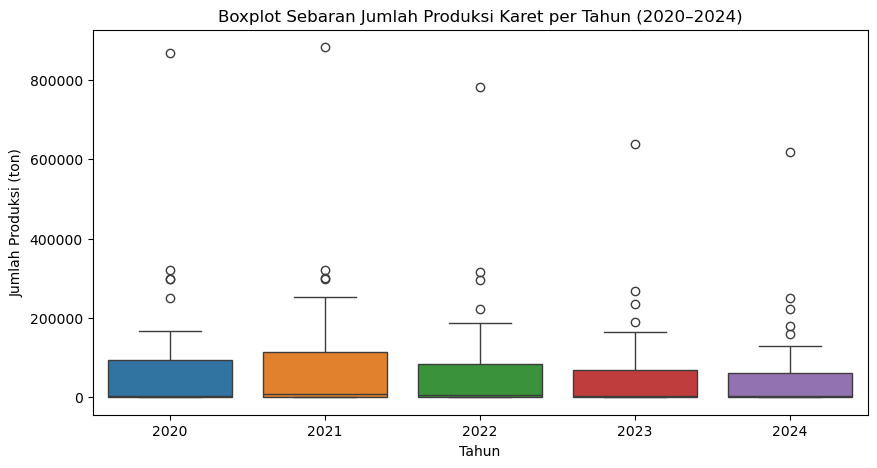

In [29]:
# 202431026_Purnomo Jeremy Bambang
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[cols_tahun])
plt.title("Boxplot Sebaran Jumlah Produksi Karet per Tahun (2020–2024)")
plt.xlabel("Tahun")
plt.ylabel("Jumlah Produksi (ton)")
plt.show()

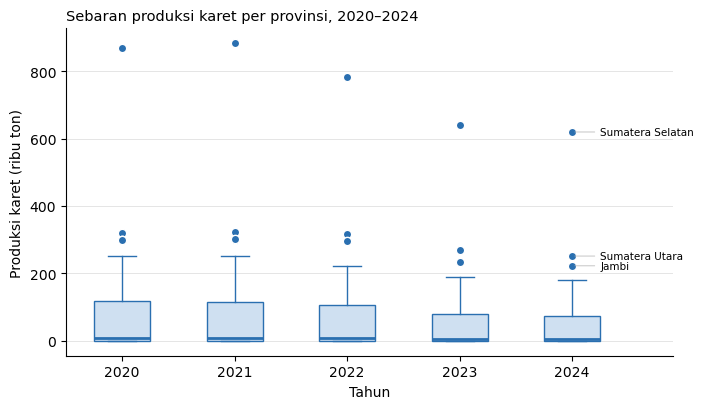

In [44]:
# 202431026_Purnomo Jeremy Bambang
fig, ax = plt.subplots(figsize=(7.2, 4.2))
warna = '#2a6fb0'
data = [df[t].dropna() / 1000 for t in cols_tahun]      # ribu ton
ax.boxplot(data, patch_artist=True, widths=0.5,
           boxprops=dict(facecolor='#cfe0f1', edgecolor=warna),
           medianprops=dict(color=warna, lw=2),
           whiskerprops=dict(color=warna), capprops=dict(color=warna),
           flierprops=dict(marker='o', markerfacecolor=warna,
                           markeredgecolor='white', markersize=6))
ax.set_xticklabels(cols_tahun)

# label provinsi outlier tahun 2024 (batas atas IQR)
q1, q3 = df['2024'].quantile([0.25, 0.75]) / 1000
batas = q3 + 1.5 * (q3 - q1)
outlier = df[df['2024'] / 1000 > batas].sort_values('2024', ascending=False)
terakhir = 1e9
for _, row in outlier.iterrows():
    v = row['2024'] / 1000
    y_teks = min(v, terakhir - 26)       # geser supaya label tidak bertumpuk
    terakhir = y_teks
    ax.annotate(row['Provinsi'], (5, v), xytext=(5.25, y_teks),
                fontsize=7.5, va='center',
                arrowprops=dict(arrowstyle='-', color='#bbbbbb', lw=0.6))

ax.set_xlim(0.5, 5.9)
ax.set_xlabel('Tahun'); ax.set_ylabel('Produksi karet (ribu ton)')
ax.set_title('Sebaran produksi karet per provinsi, 2020–2024', loc='left', fontsize=10.5)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.grid(axis='y', color='#e5e5e5', lw=0.7); ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### Deteksi Outlier (IQR)

In [30]:
# 202431026_Purnomo Jeremy Bambang
for t in cols_tahun:
    Q1, Q3 = df[t].quantile([0.25, 0.75])
    batas_atas = Q3 + 1.5 * (Q3 - Q1)
    out = df[df[t] > batas_atas]['Provinsi'].tolist()
    print(f"{t}: Q1={Q1:,.0f} Q3={Q3:,.0f} batas atas={batas_atas:,.0f} -> {len(out)} outlier: {out}")

2020: Q1=0 Q3=94,906 batas atas=237,264 -> 5 outlier: ['Sumatera Utara', 'Riau', 'Jambi', 'Sumatera Selatan', 'Kalimantan Barat']
2021: Q1=0 Q3=114,648 batas atas=286,620 -> 4 outlier: ['Sumatera Utara', 'Riau', 'Jambi', 'Sumatera Selatan']
2022: Q1=0 Q3=84,593 batas atas=211,483 -> 4 outlier: ['Sumatera Utara', 'Riau', 'Jambi', 'Sumatera Selatan']
2023: Q1=0 Q3=67,683 batas atas=169,209 -> 4 outlier: ['Sumatera Utara', 'Riau', 'Jambi', 'Sumatera Selatan']
2024: Q1=0 Q3=61,821 batas atas=154,553 -> 5 outlier: ['Sumatera Utara', 'Riau', 'Jambi', 'Sumatera Selatan', 'Kalimantan Barat']


## ANALISIS BIVARIAT

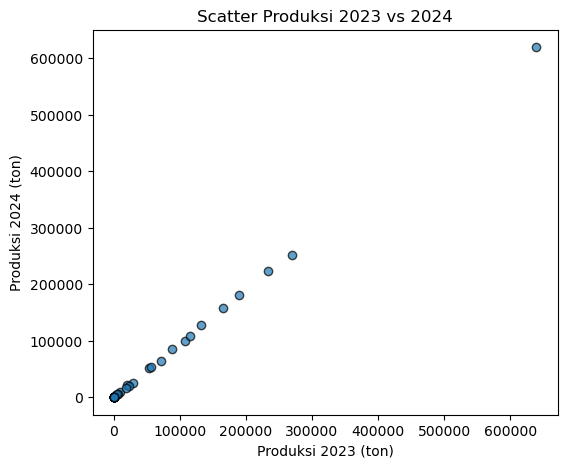

In [31]:
# 202431026_Purnomo Jeremy Bambang
plt.figure(figsize=(6, 5))
plt.scatter(df['2023'], df['2024'], alpha=0.7, edgecolors='k')
plt.xlabel('Produksi 2023 (ton)'); plt.ylabel('Produksi 2024 (ton)')
plt.title('Scatter Produksi 2023 vs 2024')
plt.show()

## ANALISIS MULTIVARIAT

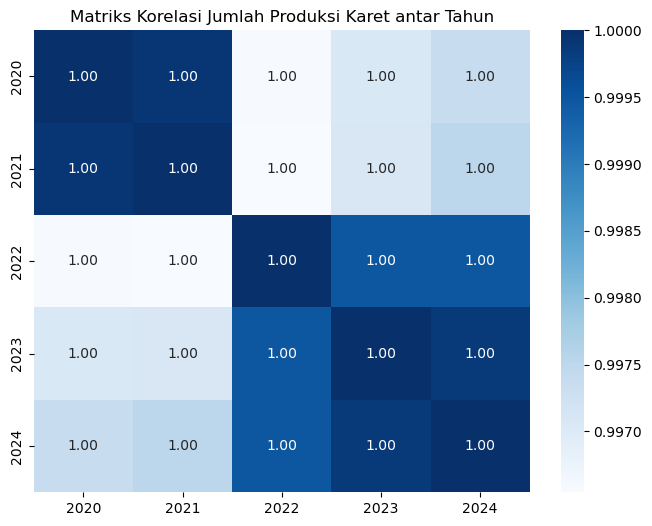

In [32]:
# 202431026_Purnomo Jeremy Bambang
plt.figure(figsize=(8, 6))
sns.heatmap(df[cols_tahun].corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Matriks Korelasi Jumlah Produksi Karet antar Tahun')
plt.show()

# PREPROCESSING

## Menghapus NaN

In [33]:
# 202431026_Purnomo Jeremy Bambang
cols_semua = ['Provinsi', '2020', '2021', '2022', '2023', '2024']
df = df.dropna(subset = cols_semua).reset_index(drop=True)
print(df.isna().sum().sum(), 'missing tersisa; jumlah baris =', len(df))

0 missing tersisa; jumlah baris = 35


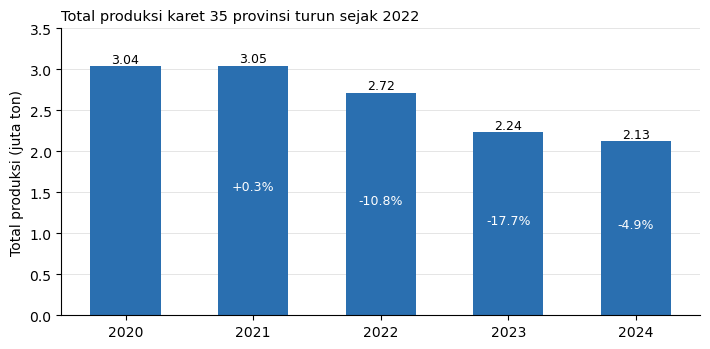

In [45]:
# 202431026_Purnomo Jeremy Bambang
tot = df[cols_tahun].sum() / 1e6                        # juta ton
fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.bar(cols_tahun, tot.values, color='#2a6fb0', width=0.55)
for i, v in enumerate(tot.values):
    ax.text(i, v + 0.04, f'{v:.2f}', ha='center', fontsize=9)
    if i > 0:
        perubahan = (v / tot.values[i - 1] - 1) * 100
        ax.text(i, v / 2, f'{perubahan:+.1f}%', ha='center', fontsize=9, color='white')
ax.set_ylabel('Total produksi (juta ton)')
ax.set_ylim(0, 3.5)
ax.set_title('Total produksi karet 35 provinsi turun sejak 2022', loc='left', fontsize=10.5)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.grid(axis='y', color='#e5e5e5', lw=0.7); ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## Menghapus Duplikat

In [34]:
# 202431026_Purnomo Jeremy Bambang
print(df.duplicated().sum())
df = df.drop_duplicates()

0


## Outlier

## PEMISAHAN VARIABEL X dan y

In [35]:
# 202431026_Purnomo Jeremy Bambang
X = df[['2020', '2021', '2022', '2023']]
y = df['2024']

## MODEL REGRESI LINEAR

In [36]:
# 202431026_Purnomo Jeremy Bambang
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.25,
                                                    random_state=42)

print(f"Jumlah sampel Data Latih (X_train): {X_train.shape[0]}")
print(f"Jumlah sampel Data Uji (X_test)  : {X_test.shape[0]}")

Jumlah sampel Data Latih (X_train): 26
Jumlah sampel Data Uji (X_test)  : 9



Jumlah sampel Data Uji (X_test)  : 9


In [37]:
# 202431026_Purnomo Jeremy Bambang
model = LinearRegression()
model.fit(X_train, y_train)
print('Intercept :', model.intercept_)
print('Koefisien :', {k: round(float(v), 4) for k, v in zip(X.columns, model.coef_)})

Intercept : -297.0798178253026
Koefisien : {'2020': -0.4722, '2021': 0.5416, '2022': 0.1551, '2023': 0.6699}


## EVALUASI MODEL REGRESI

In [38]:
# 202431026_Purnomo Jeremy Bambang
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

y_pred = model.predict(X_test)
y_pred_c = np.clip(y_pred, 0, None)   # [REVISI] produksi tidak mungkin negatif

mae = mean_absolute_error(y_test, y_pred_c)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_c))
r2 = r2_score(y_test, y_pred_c)
wape = np.abs(y_test - y_pred_c).sum() / y_test.sum() * 100

print(f"Mean Absolute Error (MAE)     : {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R² Score)          : {r2:.4f}")
print(f"WAPE (error relatif total)    : {wape:.2f}%")

Mean Absolute Error (MAE)     : 926.49
Root Mean Squared Error (RMSE): 1435.25
R-squared (R² Score)          : 0.9994
WAPE (error relatif total)    : 2.43%


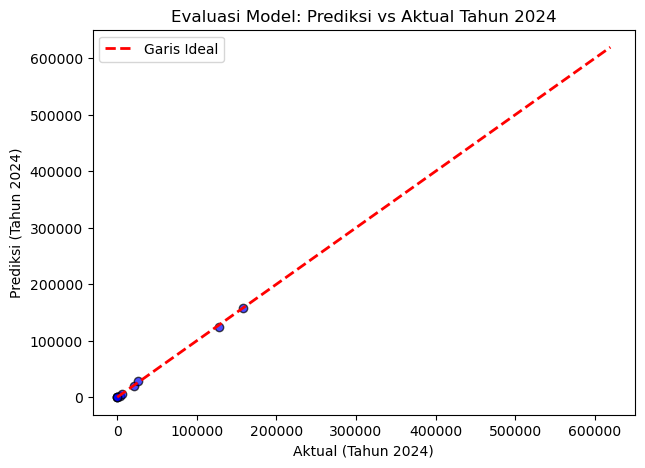

In [39]:
# 202431026_Purnomo Jeremy Bambang
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_c, color='blue', alpha=0.7, edgecolors='k')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Garis Ideal')
plt.xlabel('Aktual (Tahun 2024)')
plt.ylabel('Prediksi (Tahun 2024)')
plt.title('Evaluasi Model: Prediksi vs Aktual Tahun 2024')
plt.legend()
plt.show()

### Pembanding (baseline) & validasi silang

In [40]:
# 202431026_Purnomo Jeremy Bambang
from sklearn.model_selection import cross_val_predict, LeaveOneOut

base = X_test['2023']
print(f"Baseline (2024 = 2023) : MAE={mean_absolute_error(y_test, base):.0f}  R²={r2_score(y_test, base):.4f}  WAPE={np.abs(y_test-base).sum()/y_test.sum()*100:.2f}%")

pcv = np.clip(cross_val_predict(LinearRegression(), X, y, cv=LeaveOneOut()), 0, None)
print(f"Model, LOOCV           : MAE={mean_absolute_error(y, pcv):.0f}  R²={r2_score(y, pcv):.4f}  WAPE={np.abs(y-pcv).sum()/y.sum()*100:.2f}%")
pb = X['2023']
print(f"Baseline, seluruh data : MAE={mean_absolute_error(y, pb):.0f}  R²={r2_score(y, pb):.4f}  WAPE={np.abs(y-pb).sum()/y.sum()*100:.2f}%")

Baseline (2024 = 2023) : MAE=2008  R²=0.9969  WAPE=5.27%
Model, LOOCV           : MAE=1440  R²=0.9995  WAPE=2.37%
Baseline, seluruh data : MAE=3197  R²=0.9975  WAPE=5.26%


Model, LOOCV           : MAE=1440  R²=0.9995  WAPE=2.37%
Baseline, seluruh data : MAE=3197  R²=0.9975  WAPE=5.26%


## PREDIKSI PRODUKSI KARET TAHUN 2025

In [41]:
# 202431026_Purnomo Jeremy Bambang
model_full = LinearRegression().fit(X, y)

X_2025 = df[['2021', '2022', '2023', '2024']].copy()
X_2025.columns = ['2020', '2021', '2022', '2023']   # geser jendela 1 tahun

hasil = pd.DataFrame({'Provinsi': df['Provinsi'],
                      'Produksi 2024': df['2024'],
                      'Prediksi 2025 (mentah)': model_full.predict(X_2025)})
hasil['Prediksi 2025'] = hasil['Prediksi 2025 (mentah)'].clip(lower=0)   # [REVISI] tidak boleh negatif
hasil['Perubahan (%)'] = np.where(hasil['Produksi 2024']>0,
                                  (hasil['Prediksi 2025']/hasil['Produksi 2024']-1)*100, np.nan)

print(f"Prediksi negatif sebelum dikoreksi: {(hasil['Prediksi 2025 (mentah)']<0).sum()} provinsi")
print(f"Total 2024      : {hasil['Produksi 2024'].sum():,.0f} ton")
print(f"Total 2025 pred : {hasil['Prediksi 2025'].sum():,.0f} ton ({(hasil['Prediksi 2025'].sum()/hasil['Produksi 2024'].sum()-1)*100:.1f}%)")
hasil.sort_values('Produksi 2024', ascending=False).head(10).round(1)

Prediksi negatif sebelum dikoreksi: 14 provinsi
Total 2024      : 2,127,264 ton
Total 2025 pred : 1,825,100 ton (-14.2%)


,Provinsi,Produksi 2024,Prediksi 2025 (mentah),Prediksi 2025,Perubahan (%)
5,Sumatera Selatan,619546.0,529402.0,529402.0,-14.6
1,Sumatera Utara,251518.0,231710.7,231710.7,-7.9
4,Jambi,222556.0,204476.2,204476.2,-8.1
3,Riau,180742.0,132831.7,132831.7,-26.5
19,Kalimantan Barat,158409.0,117520.5,117520.5,-25.8
21,Kalimantan Selatan,127955.0,114300.6,114300.6,-10.7
20,Kalimantan Tengah,108294.0,99046.9,99046.9,-8.5
2,Sumatera Barat,99666.0,88088.0,88088.0,-11.6
7,Lampung,84832.0,74995.9,74995.9,-11.6
6,Bengkulu,64599.0,57060.7,57060.7,-11.7


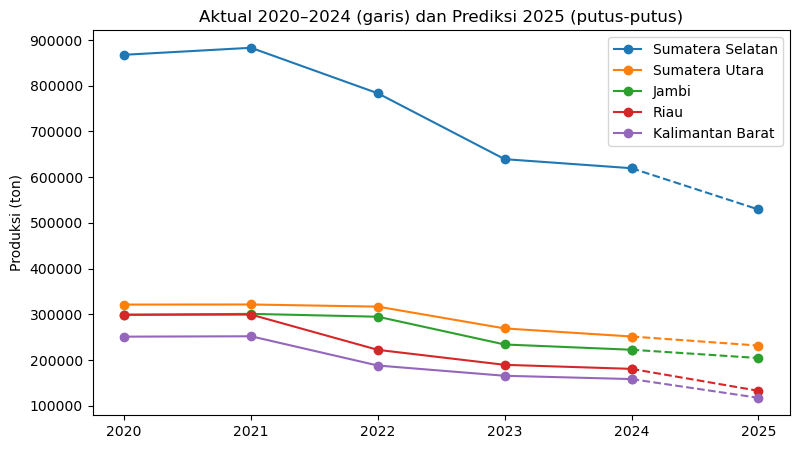

In [42]:
# 202431026_Purnomo Jeremy Bambang
# Visualisasi: 5 provinsi terbesar
tahun = ['2020','2021','2022','2023','2024']
top5 = df.sort_values('2024', ascending=False).head(5)
fig, ax = plt.subplots(figsize=(9,5))
for i, row in top5.iterrows():
    nilai = list(row[tahun])
    p = hasil.loc[i, 'Prediksi 2025']
    l, = ax.plot(tahun, nilai, marker='o', label=row['Provinsi'])
    ax.plot(['2024','2025'], [nilai[-1], p], marker='o', linestyle='--', color=l.get_color())
ax.set_title('Aktual 2020–2024 (garis) dan Prediksi 2025 (putus-putus)')
ax.set_ylabel('Produksi (ton)'); ax.legend()
plt.show()

## Verifikasi perhitungan manual Soal 2 (regresi linier sederhana, 15 provinsi)

In [43]:
# 202431026_Purnomo Jeremy Bambang
t = df.sort_values('2024', ascending=False).head(15)
xm = (t['2023']/1000).round(2).values.reshape(-1,1)
ym = (t['2024']/1000).round(2).values
m = LinearRegression().fit(xm, ym)
print(f"b1 = {m.coef_[0]:.4f}   b0 = {m.intercept_:.4f}   R² = {m.score(xm, ym):.4f}")
x24 = (t['2024']/1000).round(2).values.reshape(-1,1)
print(f"Prediksi total 2025 (15 provinsi): {m.predict(x24).sum():.2f} ribu ton (2024: {x24.sum():.2f})")

b1 = 0.9673   b0 = -2.2433   R² = 0.9997
Prediksi total 2025 (15 provinsi): 1988.77 ribu ton (2024: 2090.73)
